[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\acer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


First Five Records
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive

Dataset Shape
(50000, 2)

Missing Values
review       0
sentiment    0
dtype: int64

Sentiment Distribution
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Cleaning Reviews...
Cleaning Completed!

Naive Bayes
Accuracy : 0.8499
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      4961
           1       0.85      0.85      0.85      5039

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000


Logistic Regression
Ac

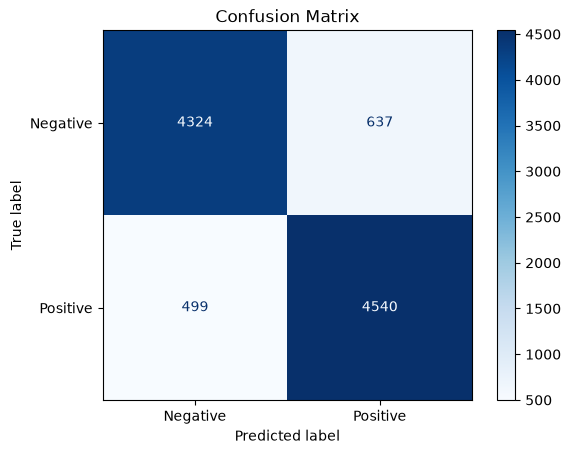


Sample Predictions

Review: This movie was absolutely fantastic. I loved every minute.
Prediction: Positive 😊

Review: Worst movie ever. Complete waste of time.
Prediction: Negative 😞


In [ ]:

import pandas as pd
import re
import string
import matplotlib.pyplot as plt
import nltk

from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

nltk.download("stopwords")
df = pd.read_csv("IMDB Dataset.csv")
print("=" * 50)
print("First Five Records")
print("=" * 50)
print(df.head())

print("\nDataset Shape")
print(df.shape)

print("\nMissing Values")
print(df.isnull().sum())

print("\nSentiment Distribution")
print(df["sentiment"].value_counts())

stop_words = set(stopwords.words("english"))

def preprocess(text):
    text = text.lower()
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = " ".join(text.split())
    words = [
        word for word in text.split()
        if word not in stop_words
    ]

    return " ".join(words)

print("\nCleaning Reviews...")

df["clean_review"] = df["review"].apply(preprocess)

print("Cleaning Completed!")

df["sentiment"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["clean_review"])

y = df["sentiment"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\n==============================")
print("Naive Bayes")
print("==============================")

nb = MultinomialNB()

nb.fit(X_train, y_train)

pred_nb = nb.predict(X_test)

print("Accuracy :", accuracy_score(y_test, pred_nb))

print(classification_report(y_test, pred_nb))

print("\n==============================")
print("Logistic Regression")
print("==============================")

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

print("Accuracy :", accuracy_score(y_test, pred_lr))

print(classification_report(y_test, pred_lr))

print("\n==============================")
print("Support Vector Machine")
print("==============================")

svm = LinearSVC()

svm.fit(X_train, y_train)

pred_svm = svm.predict(X_test)

print("Accuracy :", accuracy_score(y_test, pred_svm))

print(classification_report(y_test, pred_svm))
cm = confusion_matrix(y_test, pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")

plt.show()

def predict_sentiment(review):

    review = preprocess(review)

    vector = tfidf.transform([review])

    prediction = lr.predict(vector)

    if prediction[0] == 1:
        return "Positive 😊"
    else:
        return "Negative 😞"

print("\nSample Predictions")

review1 = "This movie was absolutely fantastic. I loved every minute."

review2 = "Worst movie ever. Complete waste of time."

print("\nReview:", review1)
print("Prediction:", predict_sentiment(review1))

print("\nReview:", review2)
print("Prediction:", predict_sentiment(review2))
while True:

    review = input("\nEnter a movie review (or type exit): ")

    if review.lower() == "exit":
        break

    print("Predicted Sentiment :", predict_sentiment(review))

print("\nProgram Finished.")